In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Список циклов (2011-2012, 2013-2014, 2015-2016, 2017-2018)
cycles = ['G', 'H', 'I', 'J']
all_data = []

for c in cycles:
    print(f"Загрузка цикла {c}...")
    
    # Загружаем нужные файлы
    demo = pd.read_sas(f'DEMO_{c}.xpt')
    bmx = pd.read_sas(f'BMX_{c}.xpt')
    dxx = pd.read_sas(f'DXX_{c}.xpt')
    diet = pd.read_sas(f'DR1TOT_{c}.xpt')
    paq = pd.read_sas(f'PAQ_{c}.xpt')
    
    # 1. Демография и тело
    #    Из BMX берем вес,рост,ИМТ,талию,плечо
    bmx_cols = [col for col in ['SEQN', 'BMXWT', 'BMXHT', 'BMXBMI', 'BMXWAIST', 'BMXARMC']
                if col in bmx.columns]
    df_merge = demo[['SEQN', 'RIDAGEYR', 'RIAGENDR']].merge(bmx[bmx_cols], on='SEQN')
    
    # 2. Состав тела (процент жира)
    df_merge = df_merge.merge(dxx[['SEQN', 'DXDTOPF']], on='SEQN')
    
    # 3. Питание (калории и БЖУ)
    df_merge = df_merge.merge(diet[['SEQN', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TTFAT']], on='SEQN')
    
    # 4. Физическая активность
    paq_cols = [col for col in ['PAQ610', 'PAD615', 'PAQ625', 'PAD630', 'PAQ640', 
                                'PAD645', 'PAQ655', 'PAD660', 'PAQ670', 'PAD675', 'PAQ650']
                if col in paq.columns]
    if paq_cols:
        df_merge = df_merge.merge(paq[['SEQN'] + paq_cols], on='SEQN', how='left')
    
    # Добавляем колонку с годом цикла (для истории)
    df_merge['cycle'] = c
    all_data.append(df_merge)

# Склеиваем все циклы в один датафрейм
df = pd.concat(all_data, ignore_index=True)

# Приводим числовые типы (read_sas иногда возвращает bytes вместо чисел)
for col in ['RIDAGEYR', 'RIAGENDR', 'BMXWT', 'BMXHT', 'BMXBMI', 'BMXWAIST', 'BMXARMC', 
            'DXDTOPF', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TTFAT']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print(f"Итоговый размер датасета: {df.shape}")

Загрузка цикла G...
Загрузка цикла H...
Загрузка цикла I...
Загрузка цикла J...
Итоговый размер датасета: (22619, 25)


In [3]:
df.columns

Index(['SEQN', 'RIDAGEYR', 'RIAGENDR', 'BMXWT', 'BMXHT', 'BMXBMI', 'BMXWAIST',
       'BMXARMC', 'DXDTOPF', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TTFAT',
       'PAQ610', 'PAD615', 'PAQ625', 'PAD630', 'PAQ640', 'PAD645', 'PAQ655',
       'PAD660', 'PAQ670', 'PAD675', 'PAQ650', 'cycle'],
      dtype='object')

In [4]:
# Считаем калории на основе БЖУ
df['calc_calories'] = (df['DR1TPROT'] * 4) + (df['DR1TCARB'] * 4) + (df['DR1TTFAT'] * 9)
# Смотрим разницу между заявленными калориями и расчетными
df['calorie_diff'] = df['DR1TKCAL'] - df['calc_calories']
# Выводим статистику разницы
print(df['calorie_diff'].describe())

count    20406.000000
mean        28.644906
std        184.574454
min       -494.120000
25%        -31.857500
50%        -15.130000
75%          0.470000
max       5735.620000
Name: calorie_diff, dtype: float64


In [5]:
# Убираем выбросы (строки с некорректно указанным количеством калорий (разница между указанным и рассчитанным больше 500))
df = df[np.abs(df['calorie_diff']) < 500]
print(df['calorie_diff'].describe())

count    19854.000000
mean         5.123909
std         91.608783
min       -494.120000
25%        -32.407500
50%        -15.920000
75%         -1.120000
max        499.050000
Name: calorie_diff, dtype: float64


In [6]:
# Удаляем строки с пропусками (NaN) в ключевых колонках
df_clean = df.dropna(subset=['RIDAGEYR', 'RIAGENDR', 'BMXWT', 'BMXHT', 'DXDTOPF', 'DR1TKCAL', 'BMXWAIST', 'BMXARMC']).copy()

print(f"Осталось строк для обучения: {len(df_clean)}")

Осталось строк для обучения: 16165


In [7]:
# Преобразуем float значения в int категориального признака "пол" ('RIAGENDR')
df_clean['RIAGENDR'] = df_clean['RIAGENDR'].astype(int)

В колонках из файла с опросом людей по их ежедневной активности есть специальные шифры, которые введены для обозначения либо отсутствия данных, либо отказа от опроса.

In [8]:
for i in ['PAD615', 'PAQ610', 'PAD630', 'PAQ625', 'PAD645', 'PAQ640', 'PAD660', 'PAQ655', 'PAD675', 'PAQ670', 'PAQ650']:
    print(f'{i}: {df_clean[i].unique()}')

PAD615: [  nan   60.  120.  360.  300.   30.  180.  480.  240.   10.   45.   90.
   20.   40.  420.   15.  780.  600.  720. 9999.  160.   25.  540.  130.
  150.   75.   12.   35.  660.  840. 1080.   36.  630.  140.   80.]
PAQ610: [nan  5.  3.  2.  6.  4.  7.  1. 99.]
PAD630: [  nan   40.   15.   60.   30.  120.  240.  420.   10.  360.  180.   45.
  300.  480.   35.  600.   90.   20.  450.  150.  840.  660.   17.  720.
 9999.  540.   80.   50.   75.  960.   31.   25.   16.   55.   70.   65.
   29.  780.  630.  105.  230.  140.]
PAQ625: [nan  5.  2.  3.  7.  4.  1.  6. 99. 77.]
PAD645: [  nan   60.   45.   27.   10.   20.   30.  120.  360.  180.   15.   90.
   25.   40.  480.  720.  300.  240.   14.   50.  540.   41.   12.  420.
   75.  150.   70.   35.  600. 9999.   11.   80.   16.   34.   37.   13.
   46.   22.  840.  115.   18.   55.   24.  140.  130.  230.  110.   42.
   17.  660.]
PAQ640: [nan  6.  7.  2.  5.  4.  1.  3. 99.]
PAD660: [  nan   60.   25.   90.   20.  120.   30.   40. 

In [9]:
# Заменяем эти коды на значение NaN (пустое значение)

# Да/Нет: 7=отказ, 9=не знает
df_clean['PAQ650'] = df_clean['PAQ650'].replace([7, 9], np.nan)

# Дни в неделю: 77=отказ, 99=не знает
for col in ['PAQ610', 'PAQ625', 'PAQ640', 'PAQ655', 'PAQ670']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].replace([77, 99], np.nan)

# Минуты в день: 7777=отказ, 9999=не знает
for col in ['PAD615', 'PAD630', 'PAD645', 'PAD660', 'PAD675']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].replace([7777, 9999], np.nan)

In [10]:
# Заменяем отсутствующие значения на 0 для колонок со средним количеством минут физической активности в день и количеством этих дней в неделю
for i in ['PAD615', 'PAQ610', 'PAD630', 'PAQ625', 'PAD645', 'PAQ640', 'PAD660', 'PAQ655', 'PAD675', 'PAQ670']:
    df_clean[i] = df_clean[i].fillna(0)

# Создаем колонки, соответствующие разным видам физической активности; рассчитываем количество минут в неделю для разных видов нагрузки, также добавляем большие веса для более высокой интенсивности активности
df_clean['work'] = (1.5 * df_clean['PAD615'] * df_clean['PAQ610']) / 7 + (df_clean['PAD630'] * df_clean['PAQ625']) / 7
df_clean['walk'] = (df_clean['PAD645'] * df_clean['PAQ640']) / 7
df_clean['sport'] = (1.5 * df_clean['PAD660'] * df_clean['PAQ655']) / 7 + (df_clean['PAD675'] * df_clean['PAQ670']) / 7

# Удаляем за ненадобностью колонки, участвующие в расчетах
df_clean = df_clean.drop(['PAD615', 'PAQ610', 'PAD630', 'PAQ625', 'PAD645', 'PAQ640', 'PAD660', 'PAQ655', 'PAD675', 'PAQ670'], axis=1)

In [11]:
df_clean.columns

Index(['SEQN', 'RIDAGEYR', 'RIAGENDR', 'BMXWT', 'BMXHT', 'BMXBMI', 'BMXWAIST',
       'BMXARMC', 'DXDTOPF', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TTFAT',
       'PAQ650', 'cycle', 'calc_calories', 'calorie_diff', 'work', 'walk',
       'sport'],
      dtype='object')

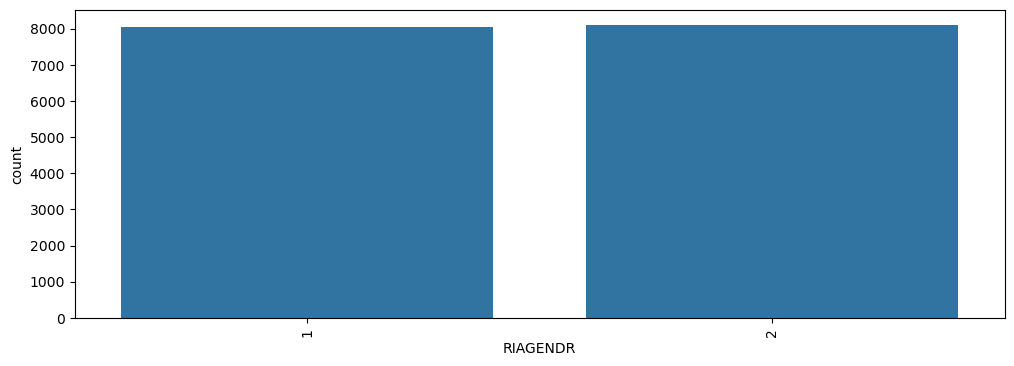

In [12]:
# Количество людей разного пола
plt.figure(figsize=(12,4))
sns.countplot(data = df_clean, x='RIAGENDR')
plt.xticks(rotation=90);

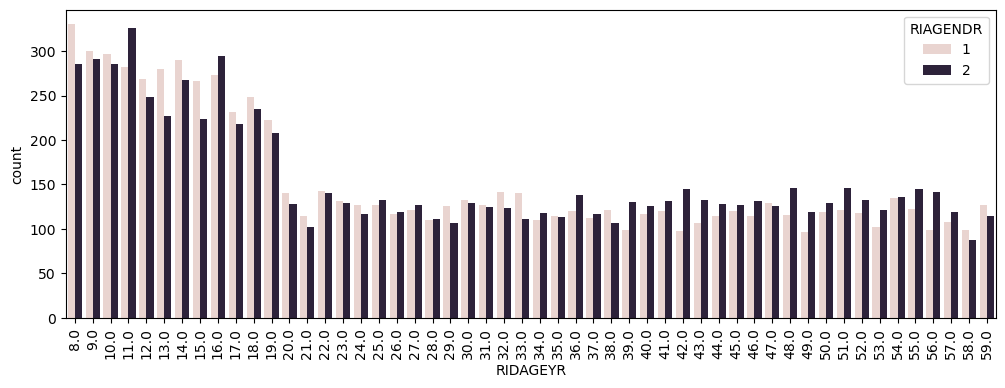

In [13]:
# Количество людей разного возраста
plt.figure(figsize=(12,4))
sns.countplot(data = df_clean, x='RIDAGEYR',hue='RIAGENDR')
plt.xticks(rotation=90);

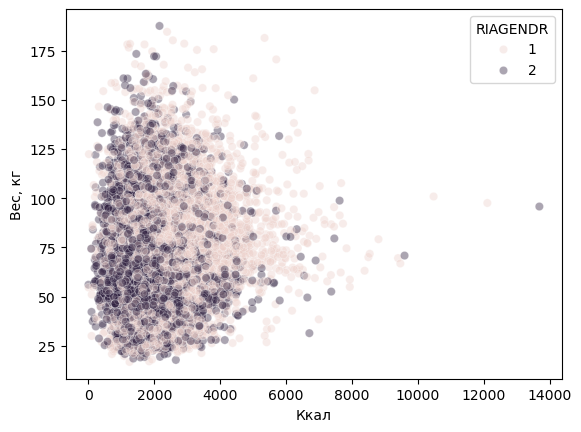

In [14]:
sns.scatterplot(data=df_clean, x='DR1TKCAL', y='BMXWT', hue='RIAGENDR', alpha=0.4)
plt.xlabel('Ккал') 
plt.ylabel('Вес, кг')
plt.show()

**Исходя из графиков, выделим следующее:** 
- выборка людей по полу практически симметрична;
- выборка по возрасту обширна, присутствуют дети (с 8 лет);
- данные по калориям достаточно шумные, это частично объясняется ошибкой в подсчетах рациона или необъективный сбор данных испытуемыми.

In [15]:
# Создаем датафрейм на основе df_clean, не включая ненужные колонки
df_work = df_clean.drop(['cycle', 'calc_calories', 'calorie_diff'], axis=1).copy()

In [16]:
# Оставляем в датафрейме только взрослых людей, убираем выбросы по калориям
df_work = df_work[(df_work['DR1TKCAL'] > 1000) & (df_work['DR1TKCAL'] < 6000) & (df_work['RIDAGEYR'] >= 18)]

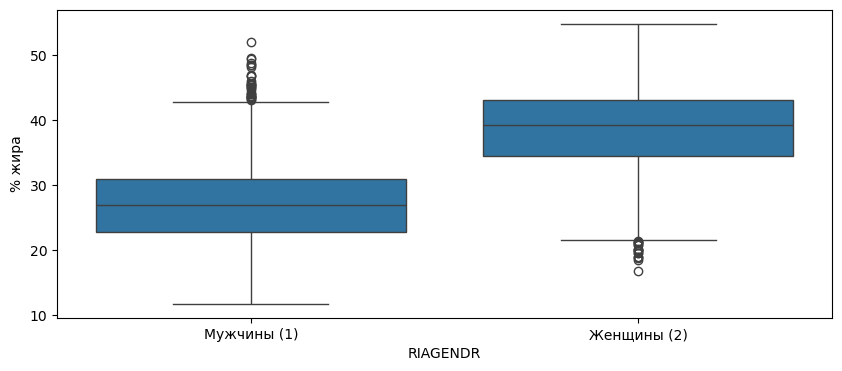

In [17]:
# Процент жира по полу

plt.figure(figsize=(10, 4))
sns.boxplot(
    data=df_work,
    x='RIAGENDR',
    y='DXDTOPF',
)
plt.xticks([0, 1], ['Мужчины (1)', 'Женщины (2)'])
plt.ylabel('% жира')
plt.show()

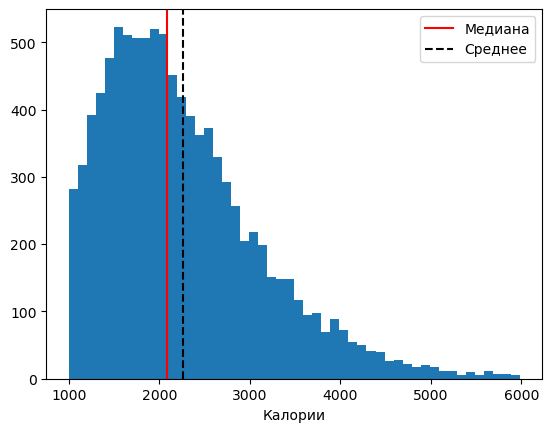

In [18]:
# Распределение калорий (медиана и среднее для наглядности)

plt.hist(df_work['DR1TKCAL'], bins=50)
plt.axvline(df_work['DR1TKCAL'].median(), color='r', label='Медиана')
plt.axvline(df_work['DR1TKCAL'].mean(), color='k', linestyle='--', label='Среднее')
plt.xlabel('Калории')
plt.legend()
plt.show()

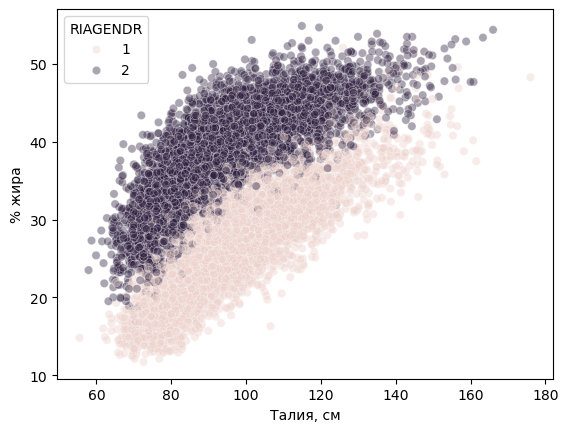

In [19]:
# Талия и процент жира

sns.scatterplot(data=df_work, x='BMXWAIST', y='DXDTOPF', hue='RIAGENDR', alpha=0.4)
plt.xlabel('Талия, см') 
plt.ylabel('% жира')
plt.show()

<Axes: >

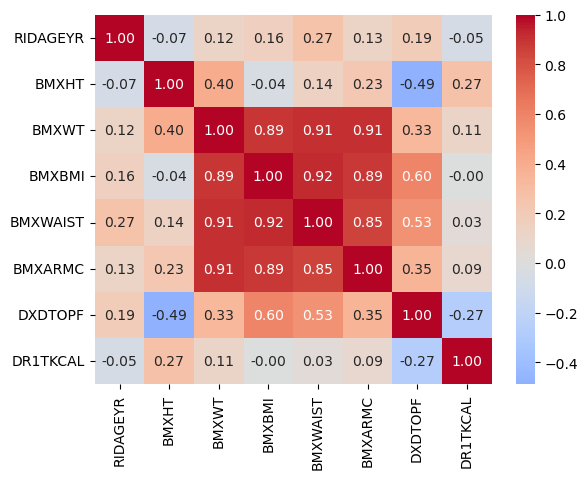

In [20]:
# Корреляционная матрица
corr_cols = ['RIDAGEYR', 'BMXHT', 'BMXWT', 'BMXBMI', 'BMXWAIST', 'BMXARMC', 'DXDTOPF', 'DR1TKCAL']
sns.heatmap(df_work[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)

## Определение процента жира по разным наборам признаков

In [21]:
# В данном эксперименте мы сравниваем разные наборы признаков для модели CatBoost и классической линейной регрессии.
from sklearn.model_selection import RepeatedKFold
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from catboost import CatBoostRegressor

# Создаем словарь с наборами признаков для обучения моделей на разных выборках признаков, чтобы определиться с финальным набором.
features = {'База (пол, возраст, рост, вес)': ['RIDAGEYR', 'RIAGENDR', 'BMXHT', 'BMXWT', 'BMXBMI'],
 'База + КБЖУ': ['RIDAGEYR', 'RIAGENDR', 'BMXHT', 'BMXWT', 'BMXBMI', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TTFAT'],
 'База + талия, плечо': ['RIDAGEYR', 'RIAGENDR', 'BMXHT', 'BMXWT', 'BMXBMI', 'BMXWAIST', 'BMXARMC'],
 'База + активность': ['RIDAGEYR', 'RIAGENDR', 'BMXHT', 'BMXWT', 'BMXBMI', 'work', 'walk', 'sport'],
 'База + талия, плечо + КБЖУ': ['RIDAGEYR', 'RIAGENDR', 'BMXHT', 'BMXWT', 'BMXBMI', 'BMXWAIST', 'BMXARMC', 'DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TTFAT'],
 'База + талия, плечо + активность': ['RIDAGEYR', 'RIAGENDR', 'BMXHT', 'BMXWT', 'BMXBMI', 'BMXWAIST', 'BMXARMC', 'work', 'walk', 'sport']}

# В данном эксперименте применим кросс-валидацию для получения разброса для каждого набора признаков, сравнив его в последствии с вычисленным МАЕ. Гиперпараметры модели задаем фиксированные.
# RepeatedKFold - повторяемая кросс-валидация со случайными разбиениями
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42) # n_splits - на сколько частей разбивают данные, n_repeats - сколько раз повторяют эти разбиения, всего n_splits * n_repeats отдельных обучений и тестов
y_cv = df_work['DXDTOPF'] # целевая переменная - процент жира
rows = [] # список для хранения строк соответствующим оценкам моделей для разных наборов признаков

for name, cols in features.items():
    X_cv = df_work[cols] # задаем набор признаков из словаря features
    cb_maes, lr_maes = [], [] # списки для хранения значений метрик МАЕ для CatBoost и Линейной регрессии
    for tr, va in cv.split(X_cv): # tr - номера строк для обучения, va - номера строк для проверки 
        # CatBoost — это алгоритм градиентного бустинга над деревьями решений, разработанный Яндексом. Почему актуально в данном проекте?
           # - нативно работает с категориями (без необходимости применять One-Hot Encoding);
           # - устойчива к выбросам при использовании метрики MAE (средняя абсолютная ошибка).
        cb = CatBoostRegressor(
            iterations=300, learning_rate=0.05, depth=5,
            loss_function='MAE', cat_features=['RIAGENDR'],
            random_seed=42, verbose=0
        ) # iterations — количество деревьев (итераций бустинга); learning_rate — скорость обучения (шаг градиентного спуска); depth — максимальная глубина каждого дерева;
          # loss_function — функция потерь, которую модель минимизирует в процессе обучения; cat_features — список признаков, которые считаются категориальными, будет обработан специальным образом;
          # random_seed — фиксированное начальное значение для генератора случайных чисел; verbose — уровень детализации логов обучения.
        cb.fit(X_cv.iloc[tr], y_cv.iloc[tr]) # обучаем модель CatBoost
        cb_maes.append(mean_absolute_error(y_cv.iloc[va], cb.predict(X_cv.iloc[va]))) # добавляем метрику МАЕ для CatBoost в список

        lr = LinearRegression().fit(X_cv.iloc[tr], y_cv.iloc[tr]) # обучаем модель классической линейной регрессии
        lr_maes.append(mean_absolute_error(y_cv.iloc[va], lr.predict(X_cv.iloc[va]))) # добавляем метрику МАЕ для линейной регрессии в список

    rows.append({
        'Набор': name,
        'CatBoost MAE': round(np.mean(cb_maes), 3),
        'CB ±': round(np.std(cb_maes), 3),
        'Линейная MAE': round(np.mean(lr_maes), 3),
        'LR ±': round(np.std(lr_maes), 3),
        'Разница, %': round((np.mean(lr_maes) - np.mean(cb_maes)) / np.mean(cb_maes) * 100, 2) # разница между линейной регрессией и CatBoost
    }) # добавляем словарь (будущую строку датафрейма) в список

# создаем датафрейм из списка rows со следующей информацией: состав набора, МАЕ для CatBoost, отклонение МАЕ по проверкам кросс-валидации для CatBoost,
    # МАЕ для линейной регрессии, отклонение МАЕ по проверкам кросс-валидации для линейной регрессии; разница между МАЕ CatBoost и Линейной регрессии.
pd.DataFrame(rows)

,Набор,CatBoost MAE,CB ±,Линейная MAE,LR ±,"Разница, %"
0,"База (пол, возраст, рост, вес)",2.952,0.049,3.138,0.055,6.28
1,База + КБЖУ,2.929,0.052,3.103,0.052,5.94
2,"База + талия, плечо",2.597,0.043,2.862,0.042,10.21
3,База + активность,2.870,0.042,3.087,0.048,7.56
4,"База + талия, плечо + КБЖУ",2.594,0.044,2.832,0.043,9.19
5,"База + талия, плечо + активность",2.571,0.042,2.833,0.039,10.18


Наборы признаков сравнивались кросс-валидацией (5 фолдов × 3 повтора). 

Разброс MAE между проверками (±) у CatBoost составляет около 0.04-0.05 п.п., поэтому улучшение считается устойчивым, только если оно заметно больше этой величины.

Добавление талии и обхвата плеча к базовому набору снижает MAE CatBoost с 2.952 до 2.597, то есть на 0.355 п.п., что примерно в 8 раз превышает разброс. Это устойчивое улучшение.

Добавление КБЖУ (улучшение 0.023) и активности (0.082) укладывается в один-два разброса, поэтому отличить его от случайных колебаний нельзя. Поверх талии и плеча эти признаки также ничего не добавляют (КБЖУ: 2.594 против 2.597, активность: 2.571 против 2.597, разница меньше разброса).

Таким образом, для итоговой модели выбран набор «База + талия, плечо»: самый простой из наборов, давших устойчивый прирост. CatBoost на всех наборах лучше линейной регрессии на 6-10%.

## Определение процента жира на основе антропометрии

In [22]:
# Рассмотрим подробнее модели с набором признаков, которые мы выбрали в качестве основного.
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from catboost import CatBoostRegressor

cols = features['База + талия, плечо']
X_fat, y_fat = df_work[cols], df_work['DXDTOPF']

# 1. Разделяем тестовые данные
X_trv, X_test, y_trv, y_test = train_test_split(X_fat, y_fat, test_size=0.2, random_state=42)
# 2. Из остального выделяем данные валидации для early stopping
X_train, X_val, y_train, y_val = train_test_split(X_trv, y_trv, test_size=0.15, random_state=42)

final_model = CatBoostRegressor(
    iterations=1000, learning_rate=0.05, depth=5,
    loss_function='MAE', cat_features=['RIAGENDR'],
    random_seed=42, verbose=0
) # задаем потолок итераций iterations=1000
final_model.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=50) # Модель обучается на X_train, y_train; в eval_set задаем данные для валидации;
    # по вычисленной на указанным в eval_set данных ошибке работает early_stopping_rounds=50 (если 50 итераций подряд ошибка не уменьшается, обучение прекращается, и модель откатывается к лучшей итерации);
    # эта итерация "закрепляется" за моделью.

pred = final_model.predict(X_test) # применяем модель к тестовым данным
print("CatBoost  MAE:", round(mean_absolute_error(y_test, pred), 3), # вычисляем и выводим МАЕ для CatBoost
      " R2:", round(r2_score(y_test, pred), 3)) # вычисляем и выводим коэффициент детерминации R2 (показывает, какую долю разброса целевой переменной модель объясняет) для CatBoost

# Для сравнения вычислим МАЕ для среднего значения тестового набора данных
print("Среднее   MAE:", round(mean_absolute_error(y_test, [y_train.mean()] * len(y_test)), 3))

# Дополнительно рассмотрим метрики модели для линейной регрессии
lr = LinearRegression().fit(X_train, y_train)
pred_lr = lr.predict(X_test)
print("Линейная  MAE:", round(mean_absolute_error(y_test, pred_lr), 3),
      " R2:", round(r2_score(y_test, pred_lr), 3))

CatBoost  MAE: 2.715  R2: 0.843
Среднее   MAE: 7.25
Линейная  MAE: 2.969  R2: 0.815


Разница между обученными моделями и средним значением значительная. Значит, модель не выдает постоянно один прогноз и действительно видит некоторые закономерности в данных. 

Сравнивая же линейную регрессию и модель CatBoost фиксируем разницу в МАЕ и R2 (CatBoost: MAE=2.715, R2=0.843; Линейная регрессия: MAE=2.969, R2=0.815). В то же время МАЕ для среднего значения составляет 7,25. 

##### **За основу берем модель CatBoost.**

#### Дополнительно оценим вклад разных признаков при определении процента жира моделью CatBoost

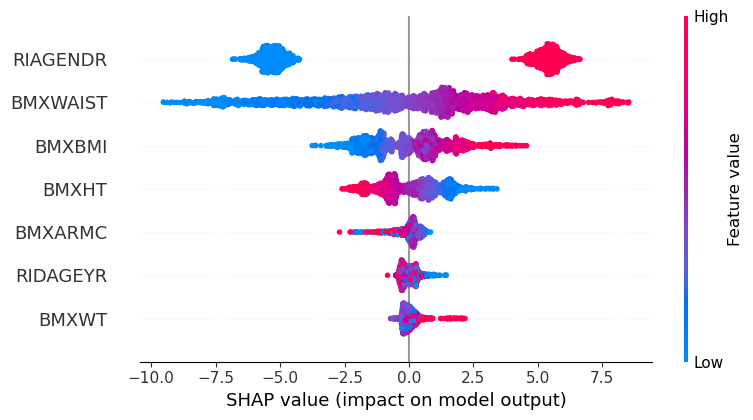

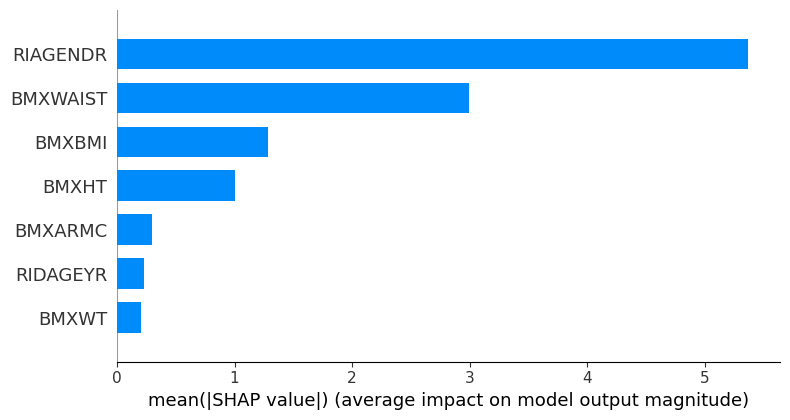

In [23]:
# Библиотека SHAP для интерпретации работы модели на основе деревьев (например, CatBoost, XGBoost, LightGBM, RandomForest). 
# SHAP даёт строго обоснованные значения вклада каждого признака для каждого прогноза
import shap

explainer = shap.TreeExplainer(final_model) # создаём специальный «объяснитель» (explainer), который позволяет эффективно вычислять количественную меру вклада каждого признака в конкретный прогноз модели
shap_values = explainer.shap_values(X_test) # считаем SHAP-значения (насколько конкретный признак сдвинул прогноз модели от среднего прогноза по обучающей выборке) для всех объектов в тестовой выборке

shap.summary_plot(shap_values, X_test) # график, отображающий важность признаков (чем выше признак - тем он важнее, цвет показывает значение признака: синий - маленькое, красный - большое)
shap.summary_plot(shap_values, X_test, plot_type="bar") # столбчатая диаграмма, отображающая важность признаков

**Наибольшее влияние при определении процента жира оказывают:**
- Пол: значение 1 (мужчины, синие точки) сдвигает прогноз примерно на −5 п.п., значение 2 (женщины, красные точки) примерно на +5 п.п. Это соответствует тому, что при прочих равных у женщин процент жира выше.
- Талия и ИМТ: большие значения (красные точки) повышают прогноз, малые (синие) понижают. Талия даёт самый широкий разброс вкладов, то есть сильнее всего различает людей между собой.
- Рост: при прочих равных более высокие люди получают более низкий прогноз.

Низкая важность веса не означает, что вес бесполезен: он тесно связан с ростом и ИМТ, и модель берёт эту информацию из них.

## Эксперимент 1 "Предсказание потребляемых человеком калорий по его антропометрии"

In [24]:
cols = ['RIDAGEYR', 'RIAGENDR', 'BMXHT', 'BMXWT', 'BMXBMI', 'BMXWAIST', 'BMXARMC'] # колонки для признаков модели 
X_kcal = df_work[cols] # признаки
y_kcal = df_work['DR1TKCAL'] # целевая переменная

X_train, X_test, y_train, y_test = train_test_split(X_kcal, y_kcal, test_size=0.2, random_state=42) # разделяем данные на тренировочные и тестовые данные

print("Среднее MAE:", round(mean_absolute_error(y_test, [y_train.mean()] * len(y_test)), 1)) # МАЕ для среднего значения
print("Медиана MAE:", round(mean_absolute_error(y_test, [y_train.median()] * len(y_test)), 1)) # МАЕ для медианого значения

cb = CatBoostRegressor(iterations=300, learning_rate=0.05, depth=5,
                       loss_function='MAE', cat_features=['RIAGENDR'],
                       random_seed=42, verbose=0).fit(X_train, y_train) # обучение модели CatBoost
lr = LinearRegression().fit(X_train, y_train) # обучение модели линейной регрессии

for name, p in [("CatBoost", cb.predict(X_test)), ("Линейная", lr.predict(X_test))]:
    print(f"{name}: MAE {mean_absolute_error(y_test, p):.1f}, R2 {r2_score(y_test, p):.3f}") # выводим МАЕ и R2 для CatBoost и линейной регрессии

Среднее MAE: 690.2
Медиана MAE: 676.8
CatBoost: MAE 639.2, R2 0.065
Линейная: MAE 643.1, R2 0.098


МАЕ для обученных моделей CatBoost и линейной регрессии (МАЕ 639 и 643 соответственно) лишь немного лучше среднего значения и медианы (МАЕ 690 и 677 соответственно). 

Из коэффициентов детерминации моделей, видим, что они объясняют порядка 6-10 % разброса целевой переменной, что является крайне малым показателем. Такие показатели говорят о том, что **предсказание суточного рациона тяжело поддается прогнозу исходя из имеющихся данных**. 

По большей части, это можно связать с необъективной оценкой или неправильным подсчетом участниками эксперимента своего 24-часового рациона (кто-то неправильно считает калораж, кто-то завышает или занижает данные, кто-то недавно изменил рацион и т.д.).

### Эксперимент 2 "По каким наборам признаков возможно сделать вывод, занимается ли человек спортом?"

In [25]:
print(df_work['PAQ650'].isna().sum()) # проверяем, есть ли отсутствующие значения для целевой переменной

0


Доля класса 1: 0.333
                                    Набор    AUC  Accuracy
0                           Антропометрия  0.713     0.708
1                    Антропометрия + КБЖУ  0.719     0.705
2                  Антропометрия + % жира  0.721     0.714
3  Антропометрия + время работы, прогулок  0.723     0.716
4            Антропометрия + время спорта  0.956     0.881

Отчет по классификации для набора 'Антропометрия'
                     precision    recall  f1-score   support

Обычный человек (0)       0.73      0.91      0.81      1313
      Спортсмен (1)       0.62      0.31      0.42       656

           accuracy                           0.71      1969
          macro avg       0.68      0.61      0.61      1969
       weighted avg       0.69      0.71      0.68      1969

Матрица ошибок для набора 'Антропометрия'


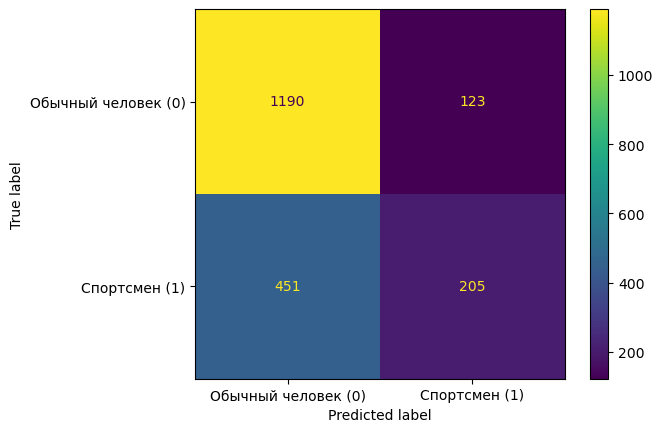

Отчет по классификации для набора 'Антропометрия + КБЖУ'
                     precision    recall  f1-score   support

Обычный человек (0)       0.72      0.90      0.80      1313
      Спортсмен (1)       0.61      0.32      0.42       656

           accuracy                           0.71      1969
          macro avg       0.67      0.61      0.61      1969
       weighted avg       0.69      0.71      0.67      1969

Матрица ошибок для набора 'Антропометрия + КБЖУ'


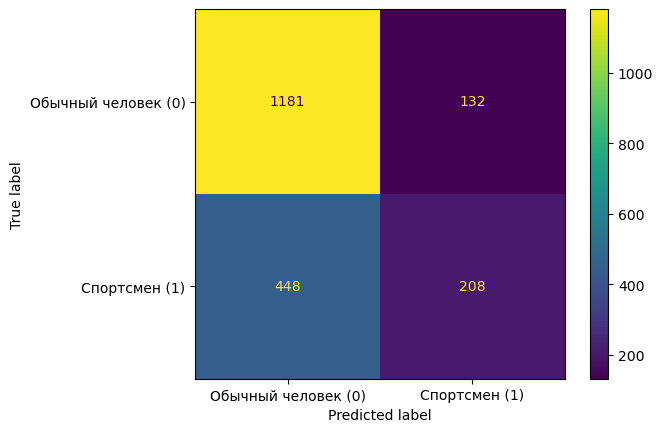

Отчет по классификации для набора 'Антропометрия + % жира'
                     precision    recall  f1-score   support

Обычный человек (0)       0.73      0.90      0.81      1313
      Спортсмен (1)       0.63      0.34      0.44       656

           accuracy                           0.71      1969
          macro avg       0.68      0.62      0.62      1969
       weighted avg       0.70      0.71      0.69      1969

Матрица ошибок для набора 'Антропометрия + % жира'


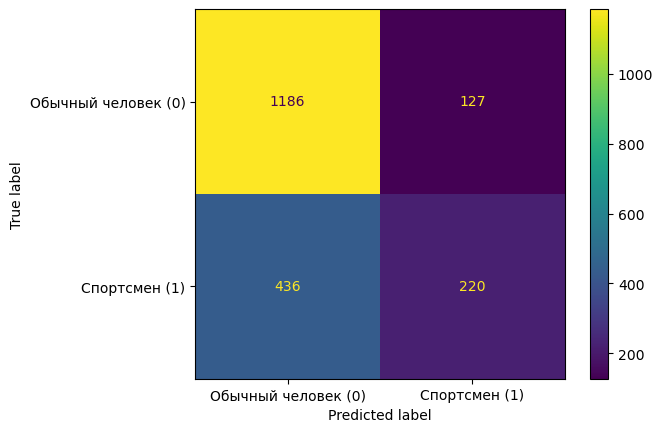

Отчет по классификации для набора 'Антропометрия + время работы, прогулок'
                     precision    recall  f1-score   support

Обычный человек (0)       0.73      0.91      0.81      1313
      Спортсмен (1)       0.65      0.32      0.43       656

           accuracy                           0.72      1969
          macro avg       0.69      0.62      0.62      1969
       weighted avg       0.70      0.72      0.68      1969

Матрица ошибок для набора 'Антропометрия + время работы, прогулок'


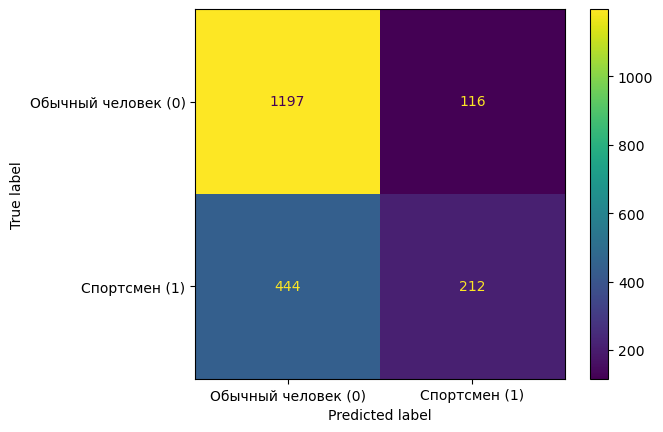

Отчет по классификации для набора 'Антропометрия + время спорта'
                     precision    recall  f1-score   support

Обычный человек (0)       0.92      0.89      0.91      1313
      Спортсмен (1)       0.80      0.85      0.83       656

           accuracy                           0.88      1969
          macro avg       0.86      0.87      0.87      1969
       weighted avg       0.88      0.88      0.88      1969

Матрица ошибок для набора 'Антропометрия + время спорта'


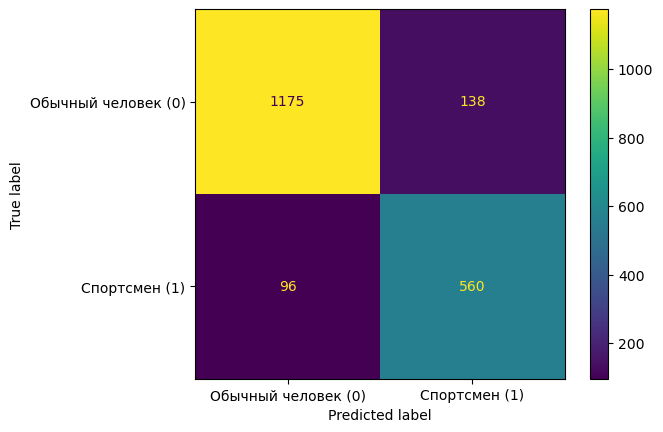

In [26]:
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from catboost import CatBoostClassifier

cols = ['RIDAGEYR', 'RIAGENDR', 'BMXHT', 'BMXWT', 'BMXBMI', 'BMXWAIST', 'BMXARMC'] # начальный (базовый) набор признаков
y_sport = (df_work['PAQ650'] == 1).astype(int) #если равно 1, преобразуем True в 1, иначе 0
print("Доля класса 1:", round(y_sport.mean(), 3)) # доля спортсменов в датафрейме

sets = {
    "Антропометрия": cols,
    "Антропометрия + КБЖУ": cols + ['DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TTFAT'],
    "Антропометрия + % жира": cols + ['DXDTOPF'],
    "Антропометрия + время работы, прогулок": cols + ['work', 'walk'],
    "Антропометрия + время спорта": cols + ['sport'],
} # наборы признаков для обучения

rows = [] # список для хранения строк датафрейма с метриками разных наборов признаков
reports = [] # список для хранения отчетов по классификации для разных наборов и матриц ошибок

for name, feats in sets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(df_work[feats], y_sport, test_size=0.2,
                                              random_state=42, stratify=y_sport) # разбиение данных для теста и обучения
        # stratify берет строки так, чтобы отношение количества значений классов оставалось таким же (df_work['PAQ650']==1)
    m = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=4,
                           cat_features=['RIAGENDR'], random_seed=42, verbose=0) # создание модели CatBoost
    m.fit(X_tr, y_tr) # обучение модели
    pred = m.predict(X_te) # предсказания модели
    p = m.predict_proba(X_te)[:, 1] #выдает не просто 0 или 1, а вероятность; это нужно для auc
    
    rows.append({
                'Набор': name,
                'AUC': round(roc_auc_score(y_te, p), 3), # метрика AUC (вычисляет площадь под ROC‑кривой — она показывает, насколько хорошо модель различает положительные и отрицательные классы)
                'Accuracy': round(accuracy_score(y_te, p > 0.5), 3), # Accuracy (вычисляет долю правильных предсказаний модели, выражение p > 0.5 превращает вероятности p в бинарные предсказания (1 — если вероятность > 0.5, иначе 0))
            }) # добавляем словарь (будущую строку датафрейма) в список

    
    reports.append({name: (classification_report(y_te, pred, target_names=['Обычный человек (0)', 'Спортсмен (1)']), # выводит подробный отчёт о качестве работы классификатора: для каждого класса и в целом показывает precision (точность), recall (полноту), F1‑score и support (число объектов в классе)
                    confusion_matrix(y_te, pred))}) # строит матрицу ошибок (путаницы) — таблицу, которая наглядно показывает, сколько и каких ошибок делает классификатор, сопоставляя истинные метки с предсказанными

sport_df = pd.DataFrame(rows)

print(sport_df)
print()

for i in reports: # выводим содержимое списка
    for n, v in i.items():
        print(f"Отчет по классификации для набора '{n}'")
        print(v[0])
        print(f"Матрица ошибок для набора '{n}'")
        disp = ConfusionMatrixDisplay(v[1], display_labels=['Обычный человек (0)', 'Спортсмен (1)']) # ConfusionMatrixDisplay визуализирует матрицу ошибок (confusion matrix) в виде понятной тепловой карты
        disp.plot() # рисуем матрицу ошибок на графике
        plt.show() # отображаем графики

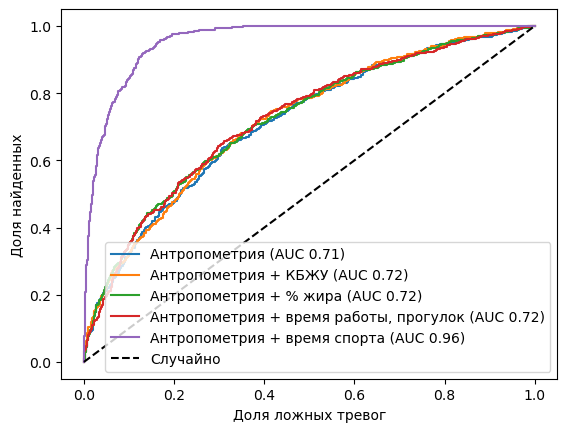

In [27]:
# Построим ROC-график для разных наборов данных
from sklearn.metrics import roc_curve, roc_auc_score

for name, feats in sets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(df_work[feats], y_sport, test_size=0.2,
                                              random_state=42, stratify=y_sport)
    m = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=4,
                           cat_features=['RIAGENDR'], random_seed=42, verbose=0)
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_te, p):.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Случайно')
plt.xlabel('Доля ложных тревог')
plt.ylabel('Доля найденных')
plt.legend()
plt.show()

Антропометрия слабо предсказывает занятия интенсивным спортом (PAQ650, самоотчёт): ROC-AUC около 0.7 при 0.5 у случайной модели, accuracy около 0.70 при 0.67 у константного прогноза «не занимается».

Добавление КБЖУ, процента жира, времени работы и прогулок значимого прироста не даёт (AUC 0.69-0.70, Accuracy 0.695-0.710).

Добавление признака sport резко повышает качество (AUC 0.952, Accuracy 0.880). Это утечка таргета: sport собран из ответов на вопросы о том же виде нагрузки, что и PAQ650, поэтому почти дублирует его. Такая модель не предсказывает занятия спортом, а пересказывает ответы анкеты.